# ⚙️✨ AutoML: автоматическая магия под капотом

Обычно классический ML-процесс включает в себя множество шагов:

* предобработка данных,
* отбор признаков,
* подбор гиперпараметров,
* обучение нескольких моделей,
* выбор лучшей.

А что, если автоматизировать большую часть этих этапов и получить сильную модель «из коробки»?
Для этого и существуют **AutoML-системы**. В этом уроке мы посмотрим, какие AutoML-решения бывают, и попробуем парочку из них в деле.

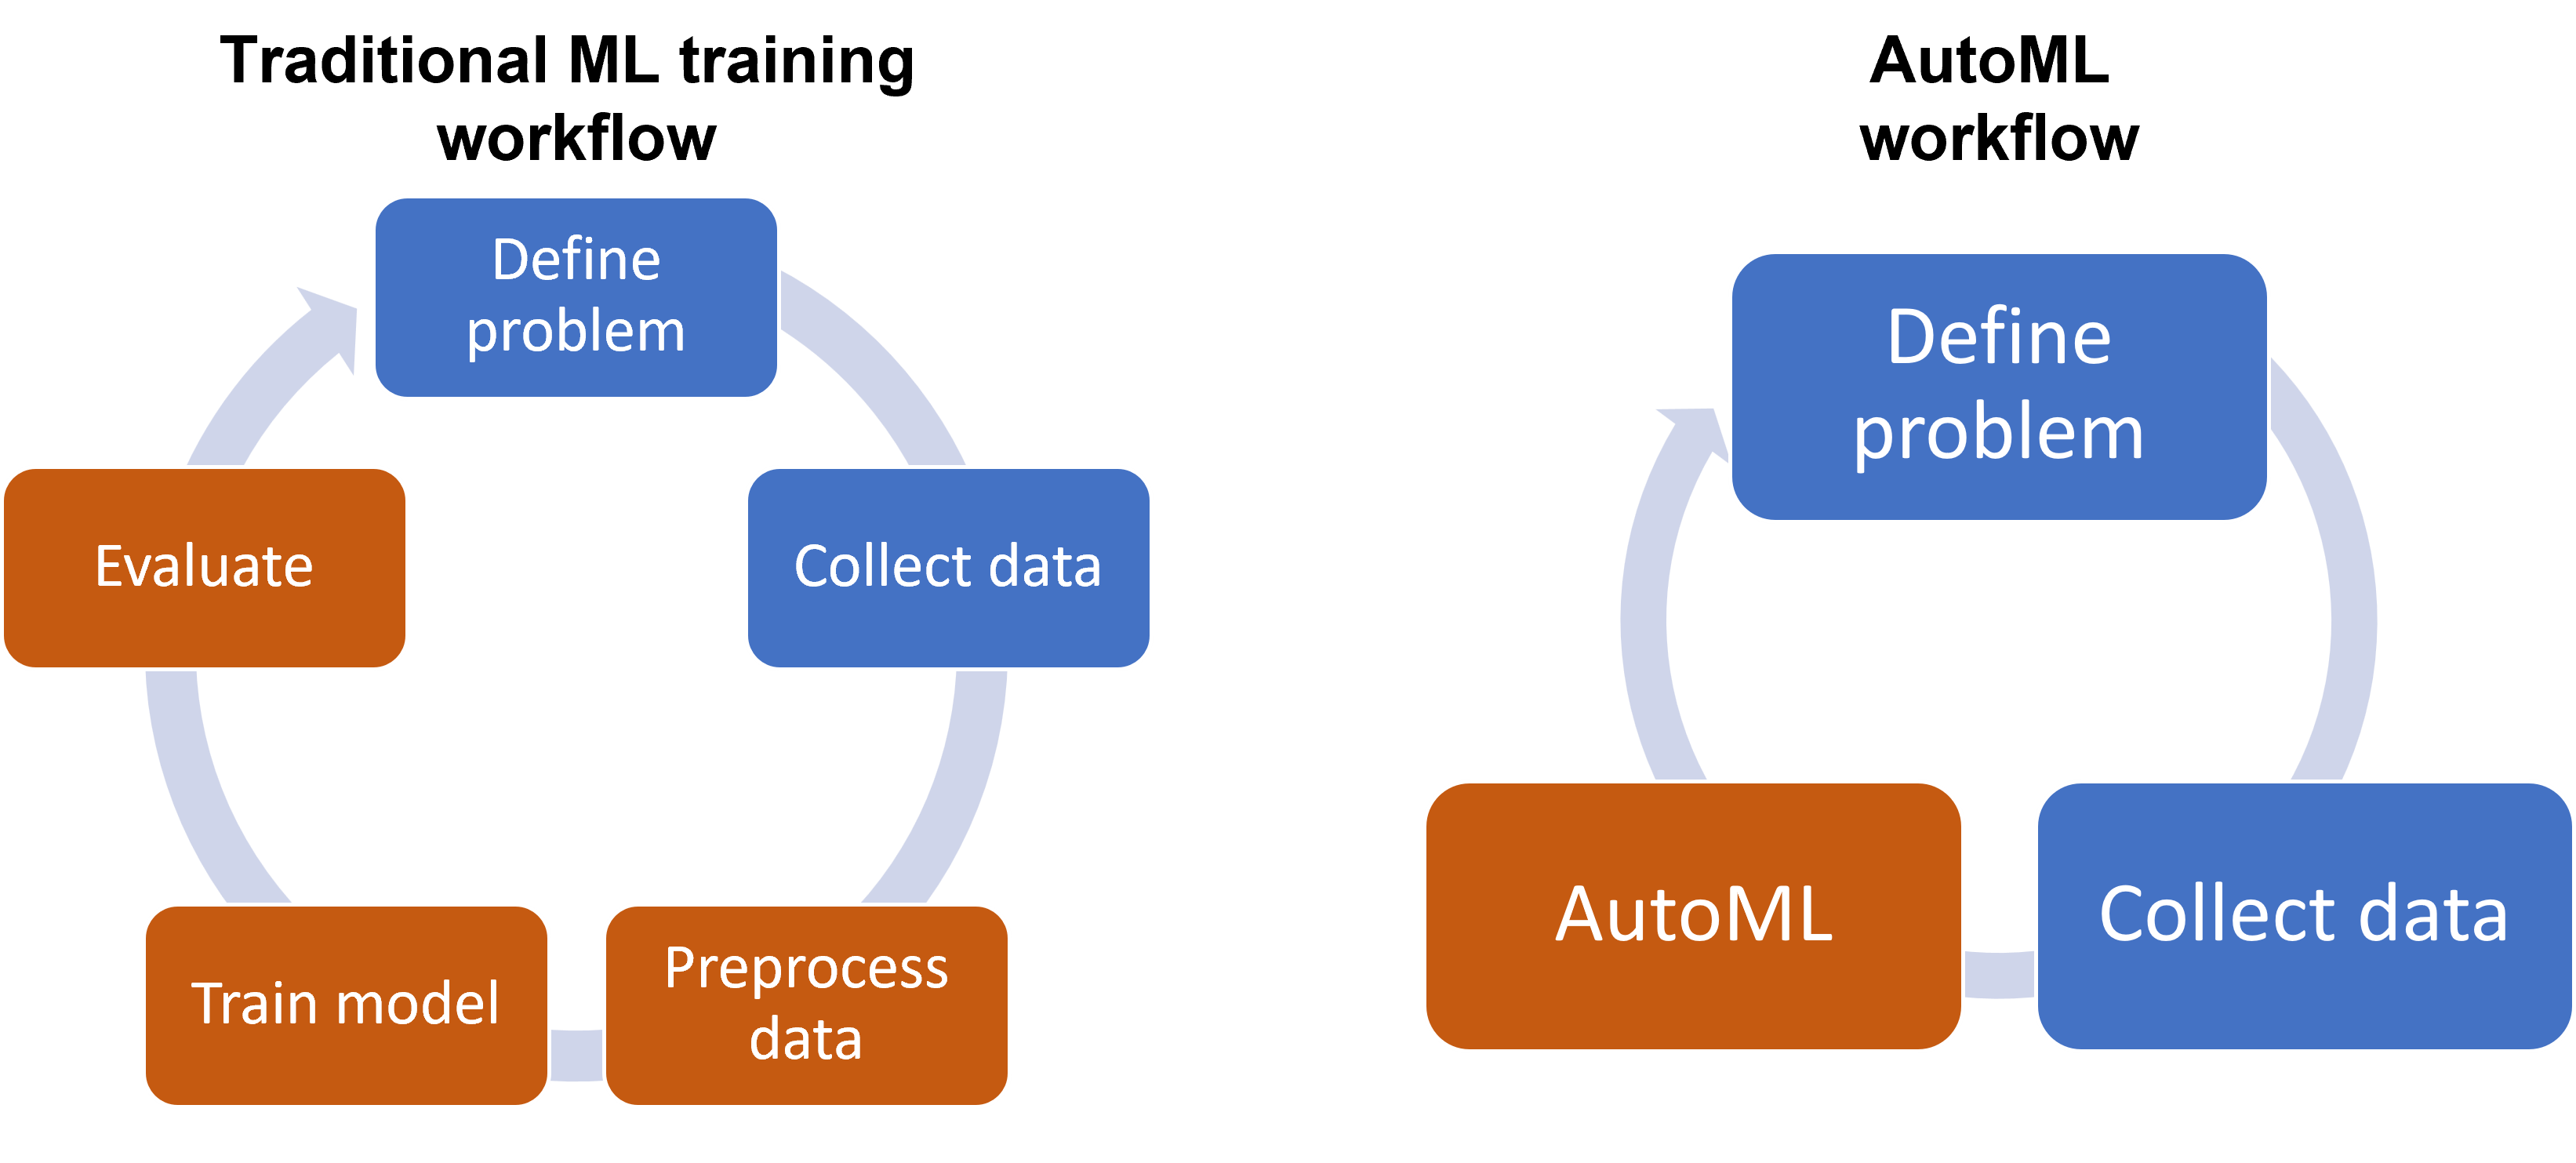

## Подготовка данных

In [ ]:
import pandas as pd

url = 'https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_churn_dataset.csv'
df = pd.read_csv(url)

df.head()

,snapshot_month,client_id,n_contacts,n_success_calls,n_fail_calls,n_sms,n_emails,bal_min_30d,bal_max_30d,bal_avg_30d,amt_sum_30d,risk_score,engagement_score,days_since_last_txn,is_term_deposit,is_credit_active,is_mobile_app_user,is_salary_client,target_churn_next
0,2025-10-31,C018653,3,1,2,2,3,9192.264947,18230.532020,12838.831495,3795.755403,67.849181,51.079443,59,1,1,1,0,0
1,2025-04-30,C013674,0,0,0,2,2,7216.543207,16477.091488,12132.905511,6015.803618,45.424803,59.016332,45,0,0,1,1,0
2,2025-06-30,C000095,7,3,4,5,2,6652.732407,11878.617645,9497.440741,3411.792130,19.435547,48.202613,53,0,0,1,1,0
3,2025-08-31,C024552,2,1,1,2,1,7326.576784,9847.075692,8915.166944,6379.017017,19.751387,65.118183,39,0,0,1,1,0
4,2025-01-31,C018243,2,1,1,2,2,7280.467732,18736.986215,13000.502866,6533.976586,60.280657,73.401334,38,1,1,1,1,0


Мы будем использовать только train и OOT.
Валидационные разбиения AutoML выполнит самостоятельно внутри обучающей выборки.

In [ ]:
# Приводим к типу datetime
df['snapshot_month'] = pd.to_datetime(df['snapshot_month'])

# Берём 80-й перцентиль для разбиения
q80 = df['snapshot_month'].quantile(0.80)
print('80% квантиль:', q80)

# Разделяем на подвыборки
train_df = df[df['snapshot_month'] < q80].copy()
oot_df   = df[df['snapshot_month'] >= q80].copy()

print('Train shape:', train_df.shape)
print('OOT shape:  ', oot_df.shape)

80% квантиль: 2025-08-31 00:00:00
Train shape: (70107, 19)
OOT shape:   (29893, 19)


In [ ]:
target_col = 'target_churn_next'
drop_cols = ['client_id', 'snapshot_month']

train_data = train_df.drop(drop_cols, axis=1)
oot_data = oot_df.drop(drop_cols, axis=1)

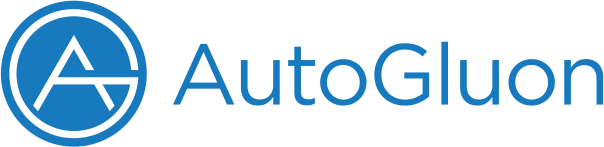

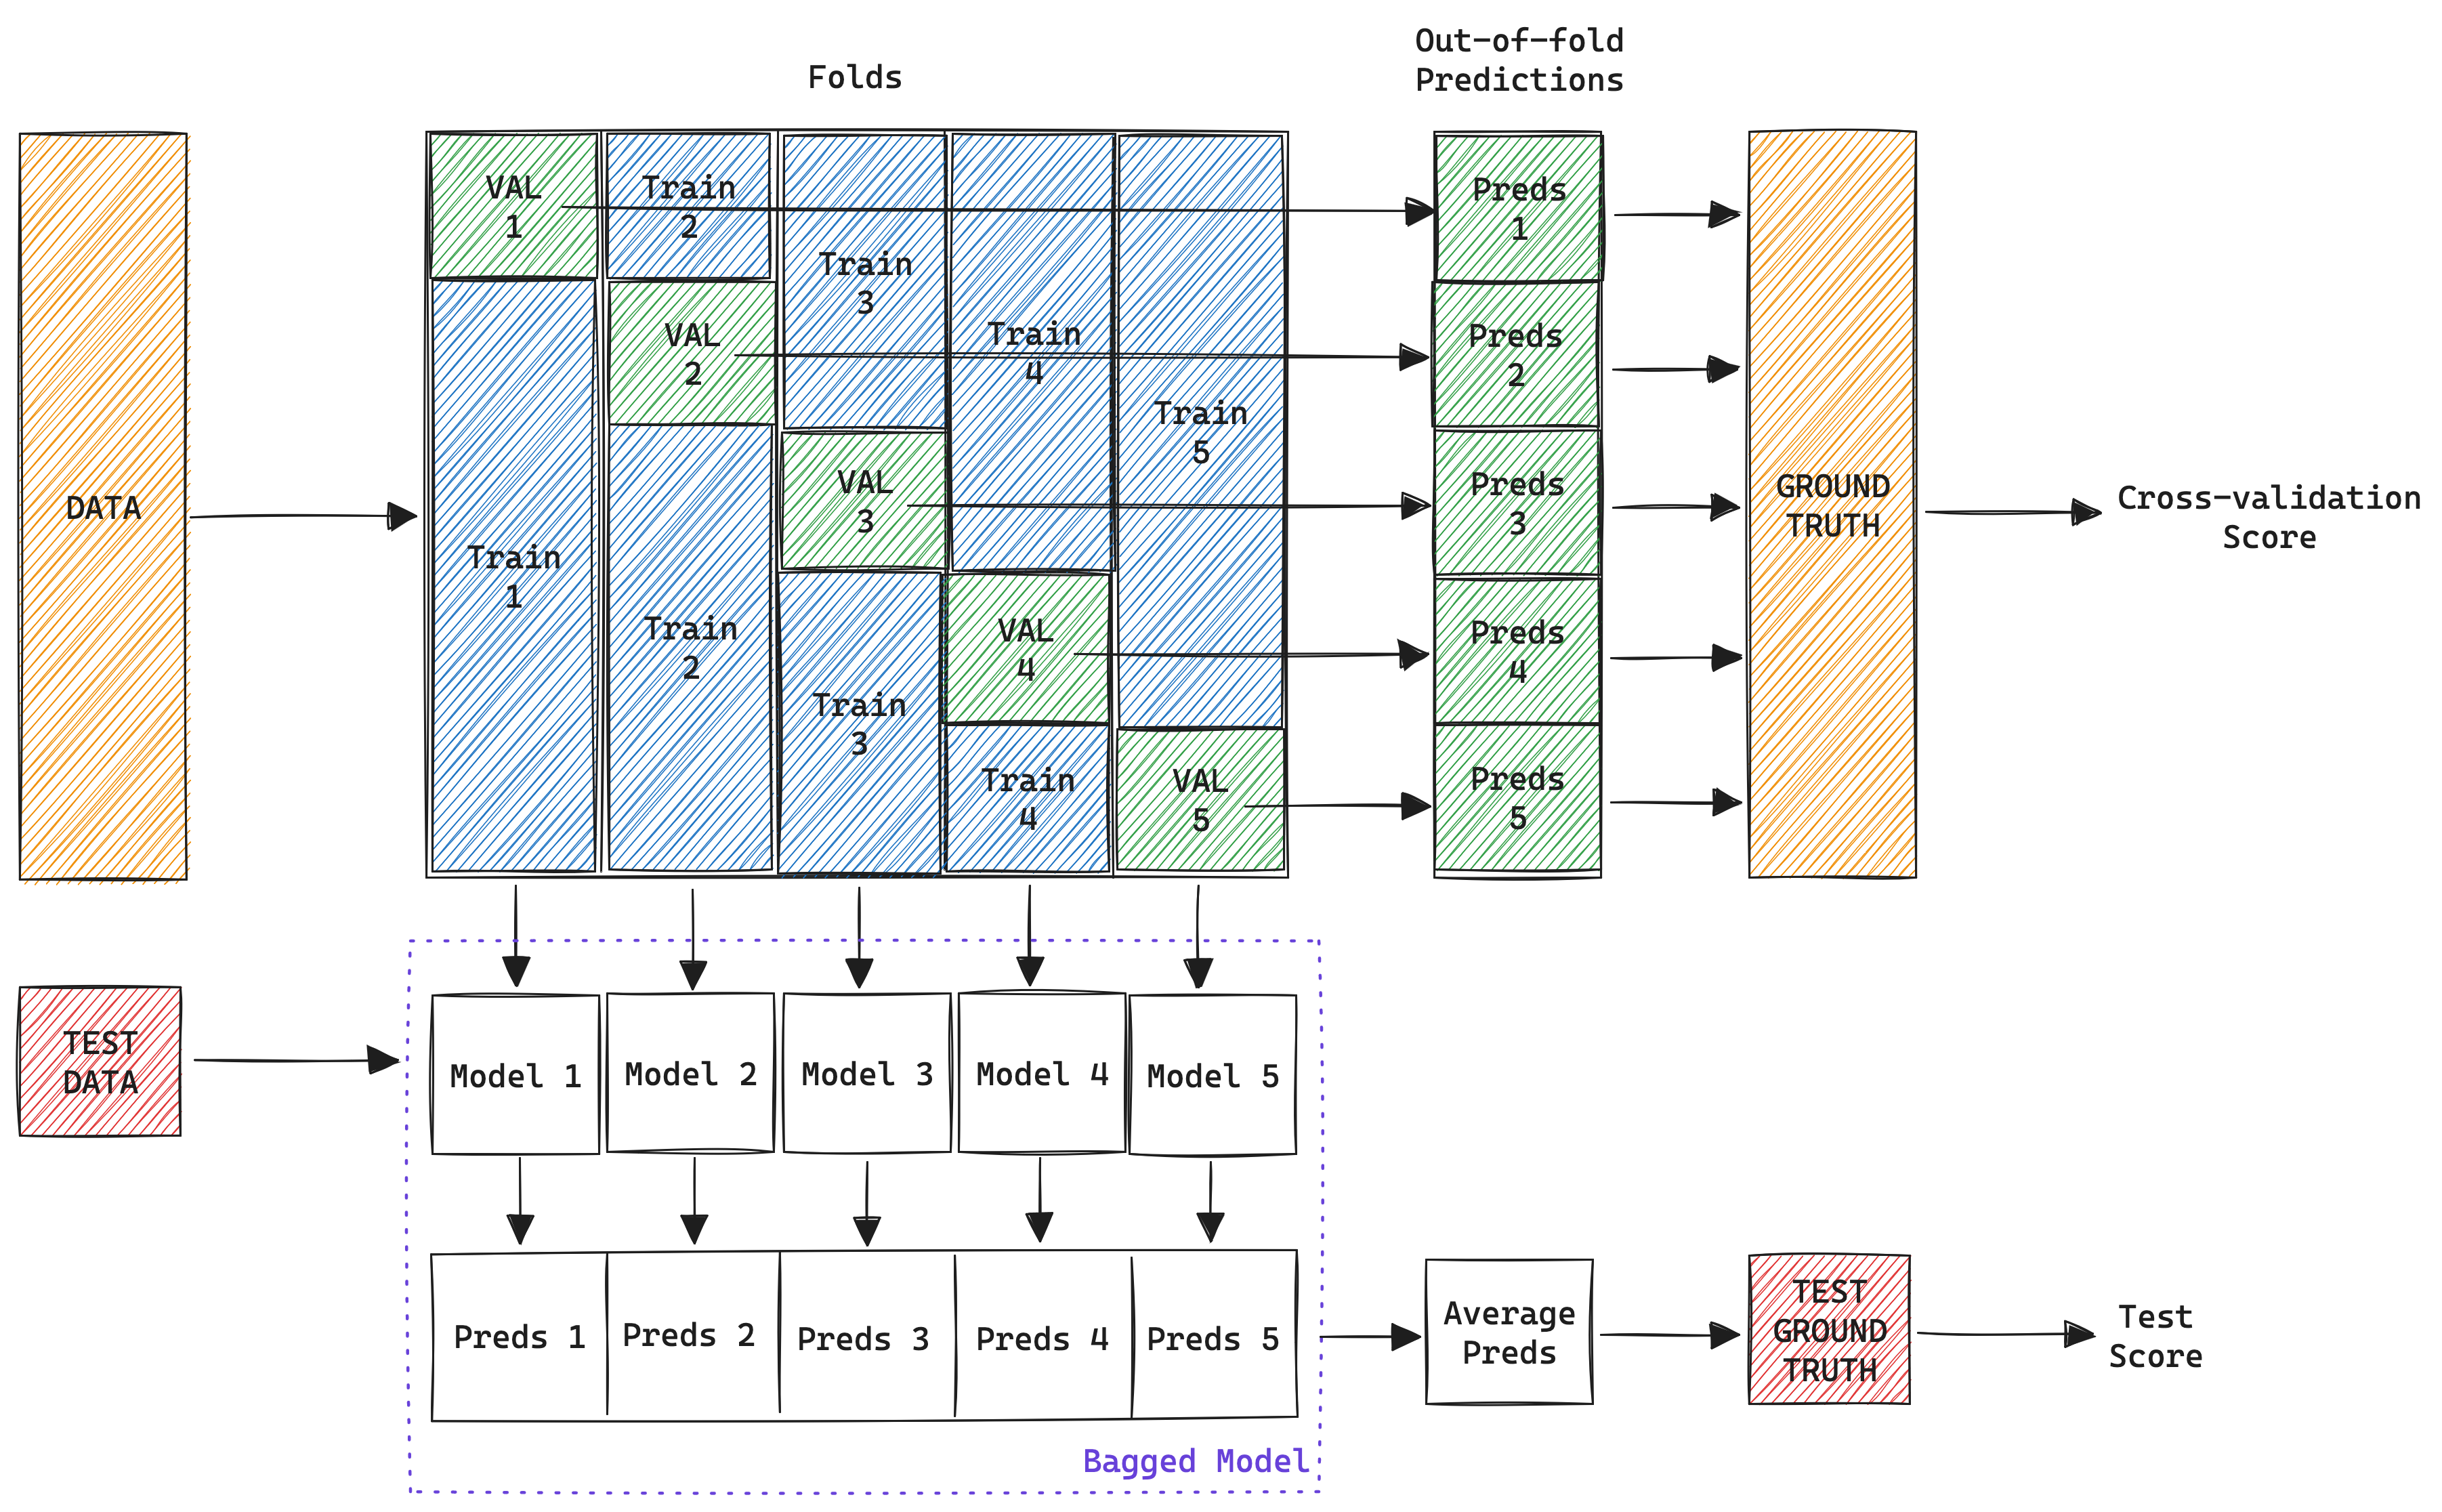

## AutoGluon

AutoGluon — AutoML от Amazon, ориентированный на высокое качество и мощные ансамбли.

## Как работает
- Определяет типы данных и автоматически их обрабатывает.
- Обучает множество моделей (GBM, CatBoost, RF, нейросети и др.).
- Активно использует stacking + bagging.
- Может проводить автоматический тюнинг гиперпараметров.
- Формирует финальный ансамбль с лучшей метрикой.

## Плюсы
- Очень высокое качество.
- Глубокое ансамблирование.
- Поддержка текстов, изображений и мультимодальных задач.

## Где применяют
- Kaggle.
- Научные ML-исследования.
- Сложные табличные задачи, где важна точность.

[ документация](https://auto.gluon.ai/stable/index.html)


In [ ]:
!pip install autogluon -q --extra-index-url https://download.pytorch.org/whl/cpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.5/259.5 kB 10.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 227.6/227.6 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.9/98.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 452.1/452.1 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 515.2/515.2 kB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.8/244.8 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.4/74.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 kB 10.6 MB/s eta 0:0

In [ ]:
from autogluon.tabular import TabularDataset, TabularPredictor

In [ ]:
time_limit = 60  # время в секундах
metric = 'roc_auc'  # валдиационная метрика
predictor = TabularPredictor(
    target_col,
    eval_metric=metric).fit(train_data,
                            time_limit=time_limit,
                            presets='medium' # самый простой режим
                            )

No path specified. Models will be saved in: "AutogluonModels/ag-20251220_120531"
Preset alias specified: 'medium' maps to 'medium_quality'.
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.12
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct  2 10:42:05 UTC 2025
CPU Count:          2
Pytorch Version:    2.9.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       11.02 GB / 12.67 GB (86.9%)
Disk Space Avail:   85.66 GB / 107.72 GB (79.5%)
Presets specified: ['medium']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 60s
AutoGluon will save models to "/content/AutogluonModels/ag-20251220_120531"
Train Data Rows:    70107
Train Data Columns: 16
Label Column:       target_churn_next
AutoGluon infers your prediction problem is: 'binary' (because only two unique label-values observed).
	2 unique label valu

In [ ]:
predictor.leaderboard()

,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.834474,roc_auc,0.055937,8.012439,0.000822,0.052855,2,True,4
1,LightGBM,0.833397,roc_auc,0.032867,2.433689,0.032867,2.433689,1,True,2
2,LightGBMXT,0.830455,roc_auc,0.022248,5.525895,0.022248,5.525895,1,True,1
3,RandomForestGini,0.814721,roc_auc,0.185192,68.901728,0.185192,68.901728,1,True,3


In [ ]:
predictor.evaluate(train_data), predictor.evaluate(oot_data)

({'roc_auc': np.float64(0.9189208601154739),
  'accuracy': 0.9391786840115823,
  'balanced_accuracy': np.float64(0.5023272160340181),
  'mcc': np.float64(0.06441805143043618),
  'f1': 0.00929368029739777,
  'precision': 0.9523809523809523,
  'recall': 0.0046696240952603316},
 {'roc_auc': np.float64(0.8441974819759105),
  'accuracy': 0.9411233399123541,
  'balanced_accuracy': np.float64(0.4999466875177708),
  'mcc': np.float64(-0.0025035275384160736),
  'f1': 0.0,
  'precision': 0.0,
  'recall': 0.0})

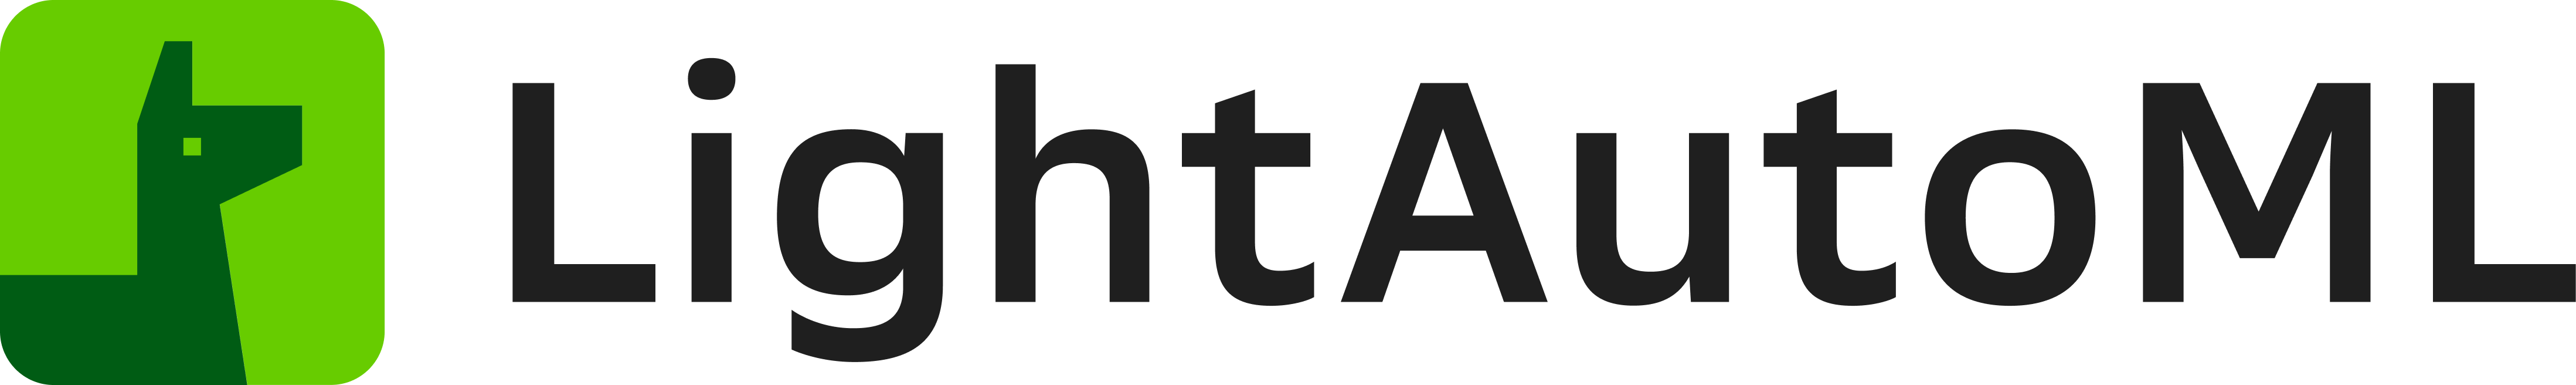

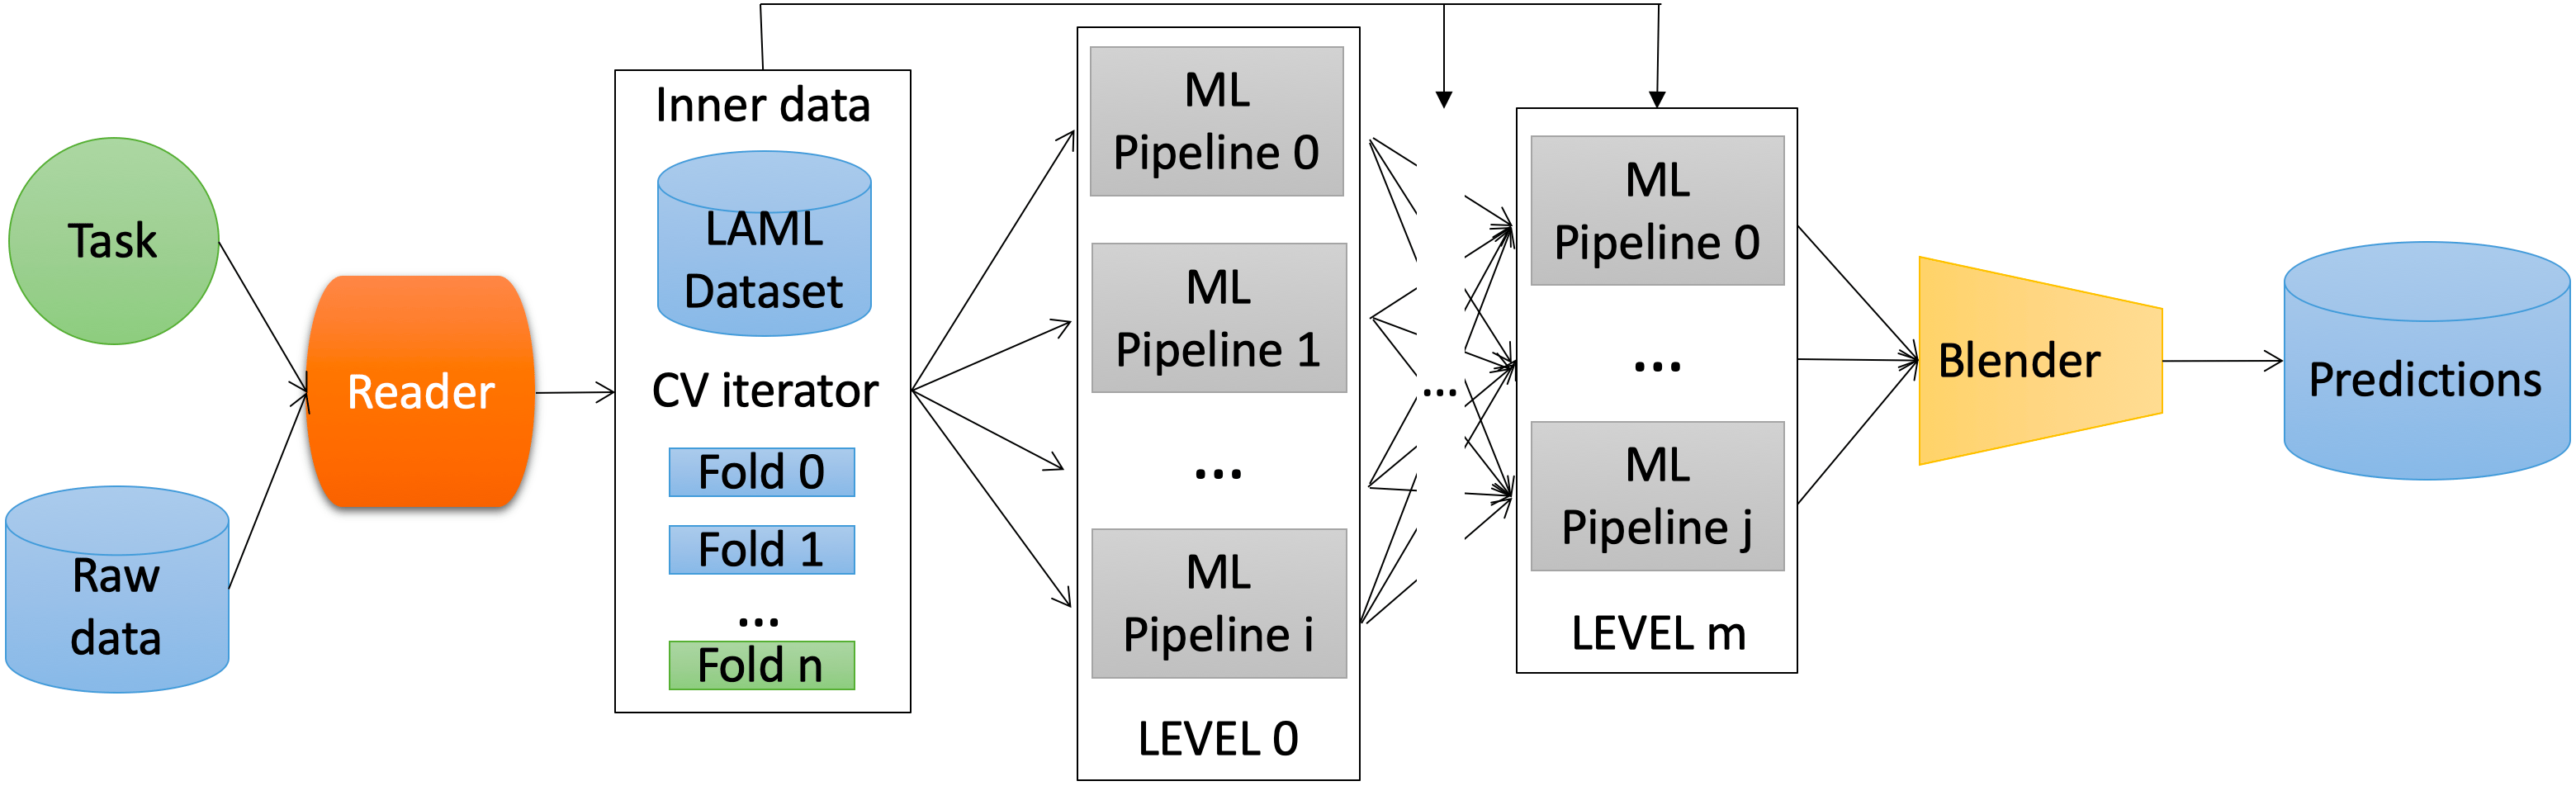

## LightAutoML (LAMA)

LightAutoML — это быстрый и интерпретируемый AutoML-фреймворк для табличных задач.

## Как работает
- Автоматически определяет типы признаков.
- Обрабатывает пропуски, кодирует категории.
- Генерирует и отбирает признаки.
- Строит пайплайн из LightGBM, CatBoost и линейных моделей.
- Делает простое ансамблирование (blending).
- Предоставляет интерпретацию через SHAP и feature importance.

## Плюсы
- Высокая скорость.
- Понятная интерпретация.
- Удобство внедрения в продакшен.

## Где применяют
- Скоринг.
- Табличный ML.
- Финтех.
- Быстрое прототипирование.

[документация](https://lightautoml.readthedocs.io/en/v.0.4.0/)

In [ ]:
!pip install numpy==1.26.4
!pip install -U 'lightautoml[all]'

  Using cached lightautoml-0.4.2-py3-none-any.whl.metadata (13 kB)
  Using cached albumentations-1.0.3-py3-none-any.whl.metadata (31 kB)
  Using cached autowoe-1.3.4-py3-none-any.whl.metadata (3.5 kB)
  Using cached cffi-1.14.5.tar.gz (475 kB)
  Preparing metadata (setup.py) ... done
  Using cached cmaes-0.12.0-py3-none-any.whl.metadata (29 kB)
  Using cached fasttext_numpy2-0.10.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (16 kB)
  Using cached featuretools-1.31.0-py3-none-any.whl.metadata (15 kB)
  Using cached json2html-1.3.0.tar.gz (7.0 kB)
  Preparing metadata (setup.py) ... done
  Using cached opencv_python-4.8.0.74-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (19 kB)
  Using cached poetry_core-1.9.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached statsmodels-0.14.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (9.0 kB)
  Using cached tabicl-0.1.4-py3-none-any.whl.metadata (13 kB)
  Using cached tabm-0.0.3-py

In [ ]:
# Standard python libraries
import os
import requests

# Essential DS libraries
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import torch

# LightAutoML presets, task and report generation
from lightautoml.automl.presets.tabular_presets import TabularAutoML, TabularUtilizedAutoML
from lightautoml.tasks import Task
from lightautoml.report.report_deco import ReportDeco, ReportDecoUtilized
from lightautoml.addons.tabular_interpretation import SSWARM

In [ ]:
N_THREADS = 4
N_FOLDS = 5
RANDOM_STATE = 42
TEST_SIZE = 0.2
TIMEOUT = 60
target_col = 'target_churn_next'

np.random.seed(RANDOM_STATE)
torch.set_num_threads(N_THREADS)

In [ ]:
task = Task('binary')

roles = {
    'target': target_col,
}

In [ ]:
automl = TabularAutoML(
    task = task,
    timeout = TIMEOUT,
    cpu_limit = N_THREADS,
    reader_params = {'n_jobs': N_THREADS, 'cv': N_FOLDS, 'random_state': RANDOM_STATE},
)

In [ ]:
%%time
out_of_fold_predictions = automl.fit_predict(train_data, roles = roles, verbose = 1)

[12:17:57] Stdout logging level is INFO.


INFO:lightautoml.automl.presets.base:Stdout logging level is INFO.


[12:17:57] Copying TaskTimer may affect the parent PipelineTimer, so copy will create new unlimited TaskTimer


[12:17:57] Task: binary



INFO:lightautoml.automl.presets.base:Task: binary



...

[12:18:36] Automl preset training completed in 38.91 seconds



INFO:lightautoml.automl.presets.base:Automl preset training completed in 38.91 seconds



[12:18:36] Model description:
Final prediction for new objects (level 0) = 
	 0.49365 * (3 averaged models Lvl_0_Pipe_0_Mod_0_LinearL2) +
	 0.50635 * (2 averaged models Lvl_0_Pipe_1_Mod_2_CatBoost) 



INFO:lightautoml.automl.presets.base:Model description:
Final prediction for new objects (level 0) = 
	 0.49365 * (3 averaged models Lvl_0_Pipe_0_Mod_0_LinearL2) +
	 0.50635 * (2 averaged models Lvl_0_Pipe_1_Mod_2_CatBoost) 



CPU times: user 39.6 s, sys: 1.77 s, total: 41.3 s
Wall time: 38.9 s


In [ ]:
print(automl.create_model_str_desc())

Final prediction for new objects (level 0) = 
	 0.49365 * (3 averaged models Lvl_0_Pipe_0_Mod_0_LinearL2) +
	 0.50635 * (2 averaged models Lvl_0_Pipe_1_Mod_2_CatBoost) 


In [ ]:
train_preds = automl.predict(train_data)
oot_preds = automl.predict(oot_data)

print(f'train score: {roc_auc_score(train_data[target_col].values, train_preds.data[:, 0])}')
print(f'oot score: {roc_auc_score(oot_data[target_col].values, oot_preds.data[:, 0])}')

train score: 0.8564626656799996
oot score: 0.8449194509180468


## Сравнение LightAutoML и AutoGluon

LightAutoML и AutoGluon решают одну задачу — автоматизацию машинного обучения, но делают это разными способами.

LAMA фокусируется на скорости, интерпретируемости и простоте продакшена. Он строит относительно лёгкий пайплайн, использует ограниченный набор моделей и делает упор на прозрачность процесса. LAMA нацелен на быстрое получение хороших результатов и детальную интерпретацию.

AutoGluon, наоборот, стремится достичь максимального качества. Он обучает большое количество разных моделей, использует глубокое ансамблирование (stacking и bagging) и при необходимости выполняет тюнинг гиперпараметров. Из-за этого он работает дольше, но обычно показывает более высокую точность.

Итог:  
LAMA — быстрый, простой и интерпретируемый инструмент.  
AutoGluon — мощный, медленный и ориентированный на достижение лучшего качества.


Помимо этих моделей, есть куча других, такие как H2O, auto-scikit, TPOT и другие.
В этом уроке разобразы самые продвинутые на мой взгляд.

бенчмарки по моделям automl https://automlbenchmark.streamlit.app/cd_diagram